# 03 小程序 - 视图与逻辑


本篇是微信小程序基础第 03 天，按原课顺序整理：页面导航 → 页面事件 → 生命周期 → WXS 脚本 → 本地生活列表页面。

资料依据：[课程网盘](https://pan.baidu.com/s/1crZTQdIZ7OSDkZIpIWkhYw?pwd=1234) 中的微信小程序基础 `day03.rar`，包括《00_小程序 - 视图与逻辑》59 页讲义、目标讲义、`学习目标.txt`、`代码.rar` 和 `资料.rar`。

`资料.rar` 提供起始项目，`代码.rar` 提供完成后的 `mp_03` 与 `local_life`。笔记中的代码用于阅读和复制，放在 Markdown 围栏里。

| 本节练习 | 配套项目与文件 |
| --- | --- |
| 导航及传参 | `mp_03/pages/home/home.*`、`pages/info/info.*` |
| 下拉刷新、WXS 大小写转换 | `mp_03/pages/message/message.*`、`utils/tools.wxs` |
| 上拉触底、随机颜色 | `mp_03/pages/home/home.*`、`pages/contact/contact.*` |
| 商家列表案例 | `local_life/pages/home/home.wxml`、`pages/shoplist/shoplist.*`、`utils/tools.wxs` |

本篇承接 02 的首页和网络请求。实际导入项目时使用自己的 AppID；原项目中的 AppID 和基础库版本属于课程环境，不需要照搬。


## 一、页面导航

页面导航就是页面之间的跳转。网页可以用 `<a>` 或 `location.href`；小程序本课使用两种方式：**声明式导航**是在 WXML 中写 `<navigator>`，**编程式导航**是在页面 JavaScript 中调用导航 API。

先分清目标是否为 tabBar 页面。`mp_03` 中 home、message、contact 已在 `app.json.tabBar.list` 中配置；info 是普通页面，需要在 `app.json.pages` 中注册。

配套 `mp_03/app.json` 的 `pages` 数组为：

```json
[
  "pages/home/home",
  "pages/message/message",
  "pages/contact/contact",
  "pages/info/info"
]
```

这是已有 `pages` 字段的值，保留同一文件中的 `window`、`tabBar` 等配置。若从 `资料.rar` 起步，需要新增 info 路径并生成四类页面文件。是否属于 tabBar 页面由 `tabBar.list` 决定，不能只看它是否写在 `pages` 中。


### 1. 声明式导航：跳转与返回

编辑 `mp_03/pages/home/home.wxml`，对应配套项目中的两个导航组件：

```xml
<navigator url="/pages/message/message" open-type="switchTab">导航到消息页面</navigator>
<navigator url="/pages/info/info" open-type="navigate">导航到info页面</navigator>
```

| 目标 | `open-type` | 说明 |
| --- | --- | --- |
| tabBar 页面 | `switchTab` | 切换到已配置的页签页面 |
| 非 tabBar 页面 | `navigate` | 打开普通页面，保留上一页 |
| 返回 | `navigateBack` | 返回已有页面栈中的页面 |

本课的跳转地址从项目根目录写起，以 `/` 开头，不带 `.wxml` 等后缀。`navigate` 是默认值，因此打开 info 时可以省略 `open-type="navigate"`；切换到 message 时不能省略 `switchTab`。

在 `pages/info/info.wxml` 中写返回组件：

```xml
<navigator open-type="navigateBack" delta="1">返回上一页</navigator>
```

`delta` 表示返回层数，默认 `1`，配套源码直接省略它：

```xml
<navigator open-type="navigateBack">后退</navigator>
```

先从 home 打开 info，再点击返回，应回到 home。如果通过自定义编译直接启动 info，没有同样的上一页路径，不能用该情形验证正常的后退导航。


### 2. 编程式导航：切换 tabBar 页面

`mp_03/pages/home/home.wxml` 的按钮绑定：

```xml
<button bindtap="gotoMessage">跳转到message页面</button>
```

在同页 `.js` 的 `Page({...})` 中定义配套方法：

```javascript
  gotoMessage() {
    wx.switchTab({
      url: '/pages/message/message'
    })
  },
```

`wx.switchTab()` 的 `url` 必须是 tabBar 页面路径，**路径后不能带参数**。点击后应选中消息页签。

导航 API 的回调含义相同：

| 参数 | 必填 | 含义 |
| --- | --- | --- |
| `url` | 跳转时必填 | 目标页面路径；switchTab 与 navigateTo 的目标类型不同 |
| `success` | 否 | 导航调用成功后的回调 |
| `fail` | 否 | 导航调用失败后的回调 |
| `complete` | 否 | 调用结束时执行，成功、失败都会进入 |

这三个回调描述的是导航调用结果，不表示目标页面中的业务请求已经完成。


### 3. 编程式导航：打开普通页面与后退

home 页按钮：

```xml
<button bindtap="gotoInfo">跳转到info页面</button>
```

home 页 `.js` 中调用 `wx.navigateTo()`，它用于非 tabBar 页面，URL 后可以携带查询参数：

```javascript
  gotoInfo() {
    wx.navigateTo({
      url: '/pages/info/info'
    })
  },
```

info 页按钮：

```xml
<button bindtap="goBack">后退</button>
```

`pages/info/info.js` 中调用 `wx.navigateBack()`：

```javascript
  goBack() {
    wx.navigateBack({
      delta: 1
    })
  },
```

`delta` 是数字，默认 `1`。讲义说明：返回层数超过现有页面数时，会返回首页；它返回的是页面栈，不是浏览器的访问历史。返回 API 也可提供 `success`、`fail`、`complete`。

点击 home 的按钮打开 info，再点击 info 的按钮返回，核对两页处理函数的名称与 WXML 绑定保持一致。


### 4. 导航传参与 `onLoad(options)`

本课在普通页面路径后传递参数：路径与参数用 `?` 分隔，键与值用 `=` 连接，多组参数用 `&` 分隔。

`mp_03/pages/home/home.wxml` 的声明式示例：

```xml
<navigator url="/pages/info/info?name=zs&age=20">跳转到info页面</navigator>
<button bindtap="gotoInfo2">跳转到info页面</button>
```

编程式示例保留配套的参数名和值：

```javascript
  gotoInfo2() {
    wx.navigateTo({
      url: '/pages/info/info?name=ls&gender=男'
    })
  },
```

接收端在 `pages/info/info.js` 的 `data` 中准备 `query: {}`，并在已有 `onLoad` 中接收：

```javascript
  onLoad: function (options) {
    console.log(options)
    this.setData({
      query: options
    })
  },
```

`options` 就是本次打开页面时传来的查询参数。声明式示例得到 `name` 和 `age`，编程式示例得到 `name` 和 `gender`；查询值按字符串处理，例如 `age` 为 `'20'`，不是数字 `20`。

分别进入 info，查看控制台的 `options` 和 AppData 中的 `query`。要在页面中使用这些参数，需要像源码一样通过 `setData` 保存；不能在 WXML 中直接读取 JavaScript 的局部变量 `options`。

**补充边界**：动态参数包含空格、`&`、`?` 等字符时，应对参数值使用 `encodeURIComponent`，避免被当成 URL 分隔符。本课固定值示例保持原样。


## 二、页面事件

本节分别处理下拉刷新和上拉触底。02 中的 JSON 配置只开启效果或设置阈值；本节在页面 `.js` 中编写事件发生后的处理逻辑。

### 1. 开启下拉刷新并配置窗口样式

下拉刷新是用户向下拉动页面后，重新加载页面数据的行为。有两种开关位置：`app.json.window` 中设置 `enablePullDownRefresh: true`，或在需要刷新的页面 JSON 中直接设置。原课推荐**给需要的页面单独开启**。

配套 `mp_03/pages/message/message.json`：

```json
{
  "usingComponents": {},
  "enablePullDownRefresh": true,
  "backgroundColor": "#efefef",
  "backgroundTextStyle": "dark"
}
```

页面 JSON 不包裹 `window`。`backgroundColor` 使用十六进制颜色，设置下拉时露出的窗口背景；`backgroundTextStyle` 只接受 `dark`、`light`，设置下拉 loading 的风格。

先编译并切换到消息页，下拉确认灰色背景与深色 loading；下一步再实现数据重置及停止刷新。


### 2. 监听下拉：重置计数并停止 loading

编辑 `mp_03/pages/message/message.*`。在已有 `data` 中保留 `count: 0`，WXML 为：

```xml
<view>count值是：{{count}}</view>
<button bindtap="addCount">+1</button>
```

配套 `.js` 中的加一方法与刷新事件：

```javascript
  addCount() {
    this.setData({
      count: this.data.count + 1
    })
  },

  onPullDownRefresh: function () {
    // console.log('触发了message页面的下拉刷新')
    this.setData({
      count: 0
    })
    wx.stopPullDownRefresh()
  },
```

点击按钮让 count 增加，再下拉页面，`onPullDownRefresh()` 应把 count 重置为 `0`。数据处理完成后调用 `wx.stopPullDownRefresh()`，结束当前页面的下拉 loading 效果。

本例的数据重置是同步操作，所以立即停止刷新。若刷新时需要异步请求，应等本次请求结束后再停止；最后的商家列表案例会用回调完成这一步。


### 3. 监听上拉触底并设置触发距离

上拉触底指向上滚动接近页面底部后加载更多数据。页面 `.js` 的 `onReachBottom()` 负责监听事件，它本身不会自动请求下一页。

配套 `mp_03/pages/home/home.json`：

```json
{
  "usingComponents": {},
  "onReachBottomDistance": 150
}
```

`onReachBottomDistance` 的默认值为 `50px`，这里为 `150px`。它表示触发事件时距离页面底部的阈值，单位是 `px`，不是 `rpx`。

为了让页面足够长，配套 home 页 WXML 最后放一个盒子：

```xml
<view class="box"></view>
```

`pages/home/home.wxss`：

```css
/* pages/home/home.wxss */

.box {
  height: 2000rpx;
  background-color: lightblue;
}
```

home 页 `.js`：

```javascript
  onReachBottom: function () {
    console.log('触发了上拉触底的事件')
  },
```

滚动接近底部时查看控制台。页面内容不够长、没有形成页面滚动时，不能只靠写这个函数就观察到同样的触底效果。


### 4. 上拉触底案例：连续加载随机颜色

原课用颜色块演示“第一次加载 → 触底追加 → 显示 loading → 避免重复请求”。练习位于 `mp_03/pages/contact/contact.*`。

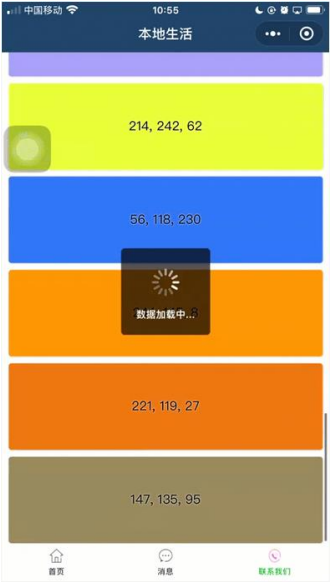

实现顺序为：定义获取颜色的方法 → 在页面加载时获取初始数据 → 渲染与美化 → 触底调用方法 → 添加 loading → 增加请求状态开关。

#### 先获取颜色并追加到数组

下面是讲义第一步的逻辑，写在 contact 页的 `Page({...})` 中：

```javascript
data: {
  colorList: [] // 随机颜色的列表
},

getColors() { // 获取随机颜色的方法
  wx.request({ // 发起请求，获取随机颜色值的数组
    url: 'https://www.escook.cn/api/color',
    method: 'GET',
    success: ({ data: res }) => {
      this.setData({
        colorList: [...this.data.colorList, ...res.data]
      })
    }
  })
},
```

`success: ({ data: res })` 把响应对象的 `data` 解构出来，命名为 `res`，它是响应正文；真正的颜色数组仍在这个正文的 `res.data` 中。它与 02 首页接口直接返回数组的写法不同。

`[...旧数组, ...新数组]` 把新颜色放到已有颜色后面。若直接覆盖旧数组，触底时就会替换列表，而不是追加。

在现有 `onLoad` 中调用 `this.getColors()`，初次进入 contact 页就会发起请求。请求的 HTTPS 与合法域名配置沿用 02，检查响应时先确认颜色数组的结构。


### 5. 用颜色值渲染列表并设置样式

课程颜色字符串形如 `214, 242, 62`，WXML 将它用于背景色并显示原始值。`mp_03/pages/contact/contact.wxml` 整理为：

```xml
<view wx:for="{{colorList}}" class="num-item"
      style="background-color: rgb({{item}});">{{item}}</view>
```

**配套代码说明**：原示例写 `rgba({{item}})`，这里按图中的三个 RGB 分量使用 `rgb(...)`；需要透明度时可明确写为 `rgba({{item}}, 1)`。原示例还写 `wx:key="index"`，它会被解释为每项的属性名，不是当前索引；本练习的颜色是字符串，又可能重复，因此不把颜色值当成保证唯一的 key。这里省略 `wx:key` 进行列表展示，实际需要稳定标识的列表应使用唯一 id。

contact 页 `.wxss` 保留配套样式：

```css
/* pages/contact/contact.wxss */
.num-item {
  border: 1rpx solid #efefef;
  border-radius: 8rpx;
  line-height: 200rpx;
  margin: 15rpx;
  text-align: center;
  text-shadow: 0rpx 0rpx 5rpx #fff;
  box-shadow: 1rpx 1rpx 6rpx #aaa;
  color: black;
}
```

`line-height` 给单行色块设置高度与垂直居中效果，`text-align` 水平居中，圆角、边框、阴影让相邻块更容易区分。

拿到数据后应看到对应颜色及 RGB 文字。若只有文字没有背景，检查颜色字符串与 `rgb(...)` 是否拼成有效颜色；这是样式检查，不需要改变请求数组的取值层级。


### 6. loading 提示与请求状态开关

先用 `wx.showLoading({ title: '数据加载中...' })` 告诉用户正在取数，再在请求的 `complete` 回调中隐藏 loading。把结束处理放在 `complete`，成功、失败都能释放状态。

配套 contact 页的状态字段拼作 `isloding`；讲义的名字是 `isloading`。两者表达同一含义，**字段的定义、赋值和读取必须保持一致**。这里保留配套拼写，`data` 为：

```javascript
data: {
  colorList: [],
  isloding: false
},
```

用下面的方法替换上一阶段的 `getColors()`：

```javascript
  getColors() {
    this.setData({
      isloding: true
    })
    // 需要展示 loading 效果
    wx.showLoading({
      title: '数据加载中...'
    })
    wx.request({
      url: 'https://www.escook.cn/api/color',
      method: 'GET',
      success: ({ data: res }) => {
        this.setData({
          colorList: [...this.data.colorList, ...res.data]
        })
      },
      complete: () => {
        wx.hideLoading()
        this.setData({
          isloding: false
        })
      }
    })
  },
```

配套代码的请求方式写作小写 `'get'`，笔记统一写为规范的 `'GET'`；其余请求地址、字段和数组取值保持配套逻辑。

再将这两个方法保留在同一个 `Page({...})` 中：

```javascript
  onLoad: function (options) {
    this.getColors()
  },

  onReachBottom: function () {
    if (this.data.isloding) return

    this.getColors()
  },
```

`isloding=false` 表示没有请求；开始请求时设为 `true`；请求结束恢复 `false`。触底时如果仍为 `true`，立即返回，避免同一请求尚未结束又发起一轮。

原课把这称作“节流阀”。本例是按请求状态阻止重叠调用，没有设置固定时间间隔。可在开发者工具中调慢网络，再观察 loading 与请求记录：上一轮未结束时连续触底，不应重复发出颜色请求。


### 7. 原课扩展：自定义编译模式

每次都从首页切换到练习页会增加操作，开发者工具可以指定本次编译的启动页面。

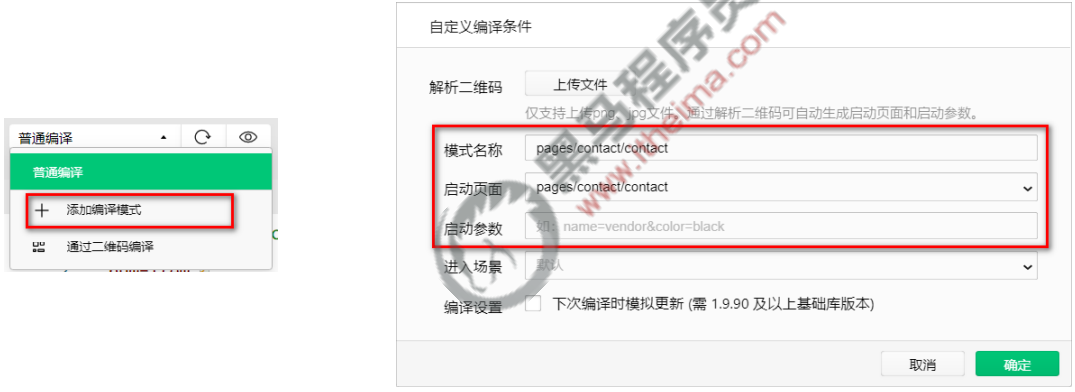

1. 打开顶部“普通编译”的下拉菜单，选择“添加编译模式”。
2. 设置模式名称，在启动页面中选 `pages/contact/contact`。
3. 此颜色案例不需要启动参数，留空并保存，再用该模式编译。

练习 message 页的刷新或 WXS 时，改选 `pages/message/message`。配套 `project.config.json` 已保存一个 message 编译模式，但仍要确认当前实际选择了哪个模式。

导航和后退练习应从 home 进入 info，保留正常的页面栈；直接启动目标页主要用于调试该页自身。


## 三、生命周期

生命周期（Life Cycle）是对象从创建、运行到销毁的整个时间段；生命周期函数是框架在特定时间点自动调用的函数，让我们在相应阶段执行操作。例如，页面加载时用 `onLoad` 初始化数据。

小程序分为应用生命周期与页面生命周期。应用描述整个小程序的启动、运行和结束；页面描述某一页的加载、渲染和卸载，范围更小。

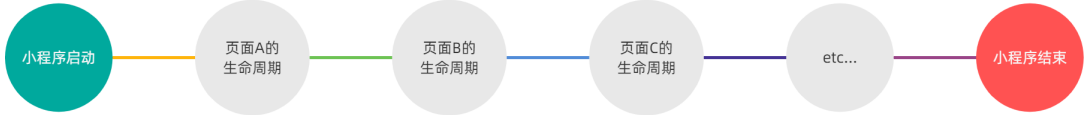

原图用于比较范围，并不表示所有页面必须按 A、B、C 的固定顺序访问。实际触发哪个页面的函数，取决于页面跳转、显示、隐藏和卸载。


### 1. 应用生命周期函数：声明在 `app.js`

| 函数 | 触发时机 |
| --- | --- |
| `onLaunch` | 小程序初始化完成，本次应用生命周期只触发一次 |
| `onShow` | 小程序启动，或从后台进入前台显示 |
| `onHide` | 小程序从前台进入后台 |

配套 `mp_03/app.js` 中与本课相关的声明如下，省略未使用的 `onError`：

```javascript
App({
  onLaunch: function () {
    // console.log('onLaunch')
  },

  onShow: function (options) {
    // console.log('onShow')
  },

  onHide: function () {
    // console.log('onHide')
  }
})
```

原文件的日志处于注释状态。练习时逐个取消 `console.log` 注释，再冷启动、切到后台、回到前台，查看各函数的触发情况。仅切换小程序内部页签，不等于把整个小程序切到后台。

同一运行期间返回前台时会再次触发 `onShow`，不等于再次初始化并触发 `onLaunch`。


### 2. 页面生命周期函数：声明在页面 `.js`

| 函数 | 时机 | 本节用法 |
| --- | --- | --- |
| `onLoad(options)` | 页面实例加载 | 接收导航参数、请求初始数据 |
| `onShow()` | 页面显示 | 观察首次显示和再次显示 |
| `onReady()` | 页面初次渲染完成 | 案例中设置导航栏标题 |
| `onHide()` | 页面隐藏 | 打开下一页或切换后观察 |
| `onUnload()` | 页面卸载 | 返回并移除当前页面时观察 |

原课的声明形式如下，放在页面 `.js` 的现有 `Page({...})` 中，不重复创建第二个 `Page`：

```javascript
Page({
  onLoad: function(options) {}, // 监听页面加载，一个页面只调用1次
  onShow: function() {},       // 监听页面显示
  onReady: function() {},      // 监听页面初次渲染完成，一个页面只调用1次
  onHide: function() {},       // 监听页面隐藏
  onUnload: function() {}      // 监听页面卸载，一个页面只调用1次
})
```

这里“只调用 1 次”指同一个页面实例。页面卸载后再重新打开，会创建新实例并再次触发 `onLoad` 和 `onReady`。`onShow` 则可以在同一实例的多次显示中触发。

可在 mp_03 的 home、info 两页现有函数中临时加入对应日志：从 home 打开 info，会看到 home 隐藏、info 加载并显示；返回时，info 卸载，home 再次显示。首次页面的常见顺序是 `onLoad → onShow → onReady`，不要把下拉与触底事件当成“每次进入页面都会按顺序运行”的生命周期函数。


## 四、WXS 脚本

WXS（WeiXin Script）是小程序的一套脚本语言，配合 WXML 做展示时的数据处理。本课的典型用途是“过滤器”：把原数据转成适合显示的形式，例如字符串大小写转换或手机号分段。

WXML 的 `{{}}` 不能直接调用在页面 `.js` 中定义的普通函数，但可以调用 WXS 模块中导出的函数。页面 `.js` 处理事件、请求和页面数据，WXS 负责本节的展示格式转换。

### 1. WXS 与 JavaScript 的关系

二者语法相似，运行环境和语言能力不同。讲义列出的数据类型包括 `number`、`string`、`boolean`、`object`、`function`、`array`、`date`、`regexp`。

| 本课 WXS 支持 | 本课 WXS 不支持 |
| --- | --- |
| `var` 定义变量、普通 `function` | `let`、`const`、箭头函数 |
| 传统对象属性写法 | 对象属性简写、解构赋值、展开运算符等 ES6 写法 |
| CommonJS 的 `module`、`module.exports`、`require()` | 不能把页面 JavaScript 的现代语法直接搬过来 |

本课通过 `module.exports` 导出成员，WXML 用模块名访问它。前面的请求代码能使用解构与展开，并不表示 `.wxs` 文件也能使用。


### 2. 内嵌 WXS：在 WXML 中把名字转为大写

在 `mp_03/pages/message/message.js` 的现有 `data` 中保留：

```javascript
username: 'zs',
```

`pages/message/message.wxml` 中的配套示例：

```xml
<view>{{m1.toUpper(username)}}</view>

<wxs module="m1">
  module.exports.toUpper = function(str) {
    return str.toUpperCase()
  }
</wxs>
```

`<wxs>` 的 `module` 必填，`m1` 是 WXML 中访问该模块的名字。`module.exports.toUpper` 把函数导出，模板再用 `m1.toUpper(username)` 调用。

编译消息页，展示结果应为 `ZS`。这个转换只改变展示值，没有通过 `setData` 把 `username` 本身改成大写。


### 3. 外联 WXS：独立文件及相对路径

编辑 `mp_03/utils/tools.wxs`，配套内容为：

```javascript
function toLower(str) {
  return str.toLowerCase()
}

module.exports = {
  toLower: toLower
}
```

这是 `.wxs` 文件，代码围栏使用 JavaScript 高亮方便阅读，不能因此把它按普通页面 JavaScript 使用。

在 message 页现有 `data` 中保留 `country: 'CHINA'`，在同页 WXML 中引用：

```xml
<view>{{m2.toLower(country)}}</view>
<wxs src="../../utils/tools.wxs" module="m2"></wxs>
```

外联引用同时需要 `module` 和 `src`。`src` **必须使用相对路径**；message 页位于 `pages/message/`，退两层才到项目根目录，再进入 `utils/`。

`toLower` 是导出的函数名，`m2` 是本页给模块指定的名字。编译后应显示 `china`，AppData 中的 `country` 仍为原来的 `CHINA`。


### 4. WXS 的使用边界

原课用下面两个写法区分展示调用与普通事件绑定：

```xml
<!-- 本课的展示调用 -->
<view>{{m2.toLower(country)}}</view>

<!-- 原课指出的错误事件绑定 -->
<button bindtap="m2.toLower">按钮</button>
```

本例的 `toLower` 接收字符串并返回展示值，不能把模块成员名当成普通 `Page` 事件处理函数名。按钮的业务事件仍按前面章节绑定到页面 `.js` 中的方法。

**版本边界补充**：讲义把这一点概括为“WXS 不能作为事件回调”。平台另有专门的 WXS 响应事件机制，本课没有使用；这里的规则针对本课这种普通字符串事件绑定，不能扩大成对所有 WXS 事件机制的结论。

WXS 与页面 JavaScript 的运行环境隔离，不能调用页面 `.js` 中的函数，也不能调用 `wx.request` 等小程序 API。因此不要在本课过滤器中发请求或更新页面 `data`。

讲义的性能说明是：iOS 设备上的 WXS 可能比 JavaScript 快 `2～20` 倍，Android 上二者运行效率无差异。这是原课介绍的环境差异，不代表任意计算都有固定加速倍数；本节只实现格式转换。


## 五、案例：本地生活列表页面

承接 02 的首页：点击九宫格分类 → 打开对应商家列表并传参 → 首次分页取数 → 上拉加载下一页 → 下拉重新加载第一页。

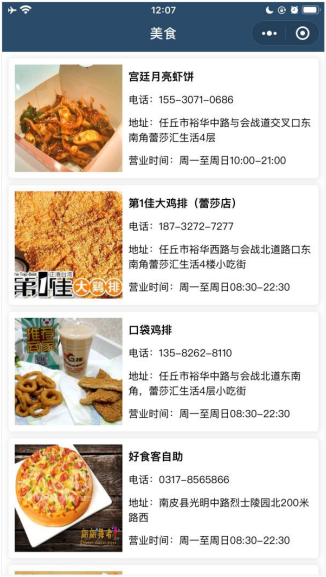

本节使用独立 `local_life` 项目。`资料.rar` 中是上一阶段的起始首页，`代码.rar` 中已经加入 shoplist 页和手机号 WXS；下面按实现过程整理。

### 1. 新建列表页并让分类可以跳转

在 `local_life/app.json` 的原 `pages` 中新增 `pages/shoplist/shoplist`，最终值为：

```json
[
  "pages/home/home",
  "pages/message/message",
  "pages/contact/contact",
  "pages/shoplist/shoplist"
]
```

保留已有 `window` 与 `tabBar`。shoplist 是普通页面，不加进 `tabBar.list`。新页面包含 `shoplist.js`、`shoplist.json`、`shoplist.wxml`、`shoplist.wxss` 四个文件。

修改 `pages/home/home.wxml` 的九宫格：把原来每项的 `view` 换为 `navigator`，保留 `grid-item` 样式、循环和图标文字：

```xml
<view class="grid-list">
  <navigator class="grid-item" wx:for="{{gridList}}" wx:key="id"
             url="/pages/shoplist/shoplist?id={{item.id}}&title={{item.name}}">
    <image src="{{item.icon}}"></image>
    <text>{{item.name}}</text>
  </navigator>
</view>
```

默认 `navigate` 打开普通页面。URL 带分类 `id` 与分类名 `title`，前者决定请求哪个列表，后者用作导航栏标题。首页的轮播、底部图片和 `home.wxss` 继续沿用 02。

点击任一分类，应进入 shoplist；下一步在 `onLoad` 中读取这两个参数。


### 2. 定义页面状态、接收参数并设置标题

编辑 `local_life/pages/shoplist/shoplist.js`，配套 `data` 为：

```javascript
data: {
  query: {},
  shopList: [],
  page: 1,
  pageSize: 10,
  total: 0,
  isloading: false
},
```

| 字段 | 当前用途 |
| --- | --- |
| `query` | 从导航接收的分类 id 与 title |
| `shopList` | 已显示的商家列表 |
| `page` | 当前请求页码，从 1 开始 |
| `pageSize` | 每页请求数量，本课为 10 |
| `total` | 当前分类的总数据条数 |
| `isloading` | 是否有请求正在进行 |

配套加载与标题设置方法：

```javascript
  onLoad: function (options) {
    this.setData({
      query: options
    })
    this.getShopList()
  },

  onReady: function () {
    wx.setNavigationBarTitle({
      title: this.data.query.title
    })
  },
```

`onLoad` 先保存 `query`，再调用获取列表的方法；若先请求，URL 中就取不到正确的分类 id。`onReady` 用 `wx.setNavigationBarTitle()` 将标题改为分类名。

这里 `isloading` 拼写正常，和 mp_03 颜色案例的 `isloding` 属于不同项目，分别保持内部一致。重新选择分类进入时应创建对应列表页，并显示该分类标题。


### 3. 分页接口与获取商家列表的方法

讲义接口：`GET https://www.escook.cn/categories/:cate_id/shops`。`:cate_id` 是路径占位符，要替换成实际分类 id，不把冒号原样写进请求地址。

| 请求参数 | 含义 | 本例取值 |
| --- | --- | --- |
| `_page` | 请求第几页 | `this.data.page` |
| `_limit` | 每页多少条 | `this.data.pageSize` |

在 `pages/shoplist/shoplist.js` 的 `Page({...})` 中加入配套方法：

```javascript
  getShopList(cb) {
    this.setData({
      isloading: true
    })
    // 展示 loading 效果
    wx.showLoading({
      title: '数据加载中...'
    })

    wx.request({
      url: `https://www.escook.cn/categories/${this.data.query.id}/shops`,
      method: 'GET',
      data: {
        _page: this.data.page,
        _limit: this.data.pageSize
      },
      success: (res) => {
        this.setData({
          shopList: [...this.data.shopList, ...res.data],
          total: res.header['X-Total-Count'] - 0
        })
      },
      complete: () => {
        // 隐藏 loading 效果
        wx.hideLoading()
        this.setData({ isloading: false })
        // wx.stopPullDownRefresh()
        cb && cb()
      }
    })
  },
```

模板字符串 `${this.data.query.id}` 把分类 id 拼进路径。成功后追加响应数组，并从 `res.header['X-Total-Count']` 读取总条数，`- 0` 将字符串转为数字。

注意各接口的数据层级：

| 代码位置 | 回调参数含义 | 取到数组的写法 |
| --- | --- | --- |
| 颜色 `success: ({ data: res })` | `res` 已经是响应正文 | `res.data` |
| 商家列表 `success: (res)` | `res` 是整个响应对象 | `res.data` |

两处都写了 `res.data`，但变量 `res` 指向的层级不同，不能机械地互相复制。

在网络面板检查分类路径、`_page=1`、`_limit=10`、响应数组和总条数响应头。原代码依赖 `X-Total-Count` 存在且能转为数字；若接口返回结构或响应头名称改变，应先对照实际响应，不能默认把缺失的总数当作加载完毕。

`complete` 隐藏请求 loading、释放状态，再按需调用 `cb`。`cb && cb()` 表示传入回调才执行，普通加载下一页可以不传；下拉刷新会传入一个停止刷新动画的回调。


### 4. 渲染商家卡片并设置样式

`local_life/pages/shoplist/shoplist.wxml` 使用配套完整结构：

```xml
<!--pages/shoplist/shoplist.wxml-->

<view class="shop-item" wx:for="{{shopList}}" wx:key="id">
  <view class="thumb">
    <image src="{{item.images[0]}}"></image>
  </view>
  <view class="info">
    <text class="shop-title">{{item.name}}</text>
    <text>电话：{{tools.splitPhone(item.phone)}}</text>
    <text>地址：{{item.address}}</text>
    <text>营业时间：{{item.businessHours}}</text>
  </view>
</view>

<wxs src="../../utils/tools.wxs" module="tools"></wxs>
```

每项用商家 `id` 作稳定 key，`images[0]` 显示第一张图，另外显示 `name`、`phone`、`address`、`businessHours`。这里的 `tools.splitPhone` 需要下一步建立 WXS 文件。

同页 `.wxss`：

```css
/* pages/shoplist/shoplist.wxss */
.shop-item {
  display: flex;
  padding: 15rpx;
  border: 1rpx solid #efefef;
  border-radius: 8rpx;
  margin: 15rpx;
  box-shadow: 1rpx 1rpx 15rpx #ddd;
}

.thumb image {
  width: 250rpx;
  height: 250rpx;
  display: block;
  margin-right: 15rpx;
}

.info {
  display: flex;
  flex-direction: column;
  justify-content: space-around;
  font-size: 24rpx;
}

.shop-title {
  font-weight: bold;
}
```

外层 Flex 横向排列缩略图与信息；图片为 `250rpx × 250rpx`，`display: block` 去掉行内排列带来的空隙；信息区域纵向分布，店名加粗。

数据到达后检查图片、店名、地址和营业时间是否与同一项响应对应。图片使用 `images[0]` 的前提是该项确实含有图片数组；旧图片地址失效时，先确认字段与地址，再处理图片显示。


### 5. 用 WXS 格式化手机号

新建 `local_life/utils/tools.wxs`，使用配套代码：

```javascript
function splitPhone(str) {
  if(str.length !== 11) return str

  var arr = str.split('')

  arr.splice(3, 0, '-')
  arr.splice(8, 0, '-')

  return arr.join('')
}

module.exports = {
  splitPhone: splitPhone
}
```

对 11 位字符串先拆成字符数组，在索引 `3` 插入第一个连字符。插入后数组已经变长，因此第二次在索引 `8` 插入连字符，最后 `join('')` 合回字符串。

例如，用于说明计算过程的 `13800138000` 会显示成 `138-0013-8000`；它是本节格式规则的演示输入，不是接口运行输出。不满 11 位时直接返回原值。

`pages/shoplist/shoplist.wxml` 通过 `../../utils/tools.wxs` 相对路径导入，并调用 `tools.splitPhone(item.phone)`。该函数按课程的手机号字符串约定编写，只做显示格式转换，不修改 `shopList` 中的原号码。


### 6. 上拉加载下一页与“数据已全部加载”

原课判断没有下一页的公式是：

```text
page * pageSize >= total
```

| 总数 | 每页数量 | 在第 7 页 | 在第 8 页 |
| --- | --- | --- | --- |
| 77 | 10 | `70 < 77`，还有下一页 | `80 >= 77`，最后一页实际为 7 条 |
| 80 | 10 | `70 < 80`，还有下一页 | `80 >= 80`，最后一页为 10 条 |

触底时先判断是否可以发请求，有下一页才增加 `page` 并调用 `getShopList()`；新结果会追加进 `shopList`。

配套代码先判断总数，再判断 `isloading`。**就地修正**：首次请求期间 `total` 尚为 `0`，先判断总数可能提前显示“数据加载完毕”。这里将加载状态判断移到前面，其余逻辑保持配套实现：

```javascript
  onReachBottom: function () {
    // 判断是否正在加载其他数据
    if (this.data.isloading) return
    if (this.data.page * this.data.pageSize >= this.data.total) {
      // 证明没有下一页的数据了
      return wx.showToast({
        title: '数据加载完毕！',
        icon: 'none'
      })
    }
    // 页码值 +1
    this.setData({
      page: this.data.page + 1
    })

    // 获取下一页数据
    this.getShopList()
  },
```

在页面 JSON 中设置触底距离，配套案例使用 `200px`，完整配置见下节。加载时连续触底应被开关阻止；上一页请求结束后再触底，请求页码才增加；满足公式时只显示提示，不发下一页请求。

**原示例边界**：页码在请求前增加，但未实现失败时回滚。若第 2 页请求失败后直接再次触底，可能跳到第 3 页；练习时用网络面板核对每次请求是否成功，发生失败可通过下拉重新加载，不把它当作已经完整取完的列表。


### 7. 下拉刷新：重置分页状态再取第一页

`local_life/pages/shoplist/shoplist.json` 的配套完整配置：

```json
{
  "usingComponents": {},
  "onReachBottomDistance": 200,
  "enablePullDownRefresh": true,
  "backgroundColor": "#efefef",
  "backgroundTextStyle": "dark"
}
```

触底距离设置为 `200px`，仅列表页开启下拉刷新，窗口为灰色背景与深色 loading。

页面 `.js` 的刷新方法保留配套逻辑：

```javascript
  onPullDownRefresh: function () {
    // 需要重置关键的数据
    this.setData({
      page: 1,
      shopList: [],
      total: 0
    })
    // 重新发起数据请求
    this.getShopList(() => {
      wx.stopPullDownRefresh()
    })
  },
```

刷新前先将 `page` 重置为 `1`、清空 `shopList`、把 `total` 重置为 `0`，再重新请求。因为获取方法使用“旧数组 + 新数组”，如果不清空列表，刷新后的第一页就会重复追加。

这次给 `getShopList` 传入回调；请求的 `complete` 触发它，调用 `wx.stopPullDownRefresh()`。成功、失败都能结束刷新动画，而不会在请求刚发出时就结束。

`wx.hideLoading()` 关闭请求时主动显示的提示，`wx.stopPullDownRefresh()` 停止页面下拉动画，作用不同。配套方法中的 `// wx.stopPullDownRefresh()` 保持注释，实际停止操作由刷新回调承担。

**原示例边界**：刷新方法没有检查正在进行的请求。前一轮未结束时下拉，会与新请求重叠，旧结果可能追加到重置后的列表；正常流程按一次请求结束后再进行下一次操作。若要避免这个情形，可在刷新方法开头补上：

```javascript
if (this.data.isloading) {
  wx.stopPullDownRefresh()
  return
}
```

这是针对当前示例的补充保护，原配套代码没有这一段。


### 8. 列表页最终有效逻辑

下面把本节逻辑合并到同一个 `Page` 中，省略没有实现内容的生命周期和分享函数。`onReachBottom` 采用上文“先判断加载状态”的修正，刷新保留原实现；请求期间的刷新保护可按上节说明补在刷新方法开头。

```javascript
Page({
  data: {
    query: {},
    shopList: [],
    page: 1,
    pageSize: 10,
    total: 0,
    isloading: false
  },

  onLoad: function (options) {
    this.setData({
      query: options
    })
    this.getShopList()
  },

  getShopList(cb) {
    this.setData({
      isloading: true
    })
    // 展示 loading 效果
    wx.showLoading({
      title: '数据加载中...'
    })

    wx.request({
      url: `https://www.escook.cn/categories/${this.data.query.id}/shops`,
      method: 'GET',
      data: {
        _page: this.data.page,
        _limit: this.data.pageSize
      },
      success: (res) => {
        this.setData({
          shopList: [...this.data.shopList, ...res.data],
          total: res.header['X-Total-Count'] - 0
        })
      },
      complete: () => {
        // 隐藏 loading 效果
        wx.hideLoading()
        this.setData({ isloading: false })
        // wx.stopPullDownRefresh()
        cb && cb()
      }
    })
  },

  onReady: function () {
    wx.setNavigationBarTitle({
      title: this.data.query.title
    })
  },

  onPullDownRefresh: function () {
    // 需要重置关键的数据
    this.setData({
      page: 1,
      shopList: [],
      total: 0
    })
    // 重新发起数据请求
    this.getShopList(() => {
      wx.stopPullDownRefresh()
    })
  },

  onReachBottom: function () {
    // 判断是否正在加载其他数据
    if (this.data.isloading) return
    if (this.data.page * this.data.pageSize >= this.data.total) {
      // 证明没有下一页的数据了
      return wx.showToast({
        title: '数据加载完毕！',
        icon: 'none'
      })
    }
    // 页码值 +1
    this.setData({
      page: this.data.page + 1
    })

    // 获取下一页数据
    this.getShopList()
  }
})
```

首页分类负责传参，列表页负责分页取数，WXML 遍历数组，WXS 只格式化电话。它们通过 `query`、`shopList`、`page`、`total`、`isloading` 对应起来。


### 9. 按操作顺序验证案例

1. **页面与导航**：确认 shoplist 已注册但不属于 tabBar；从首页点击分类进入，检查 `query.id`、`query.title` 与所点分类相同。
2. **标题与首次取数**：检查分类标题，查看 `/categories/实际id/shops` 的 GET 请求，第一页为 `_page=1`、`_limit=10`。
3. **响应与渲染**：确认数组及总数响应头，再看商家图片、名称、电话、地址和营业时间；电话按本课规则分段。
4. **上拉加载**：滚动接近底部，请求页码增加，原有商家仍在列表中，新数据追加；请求期间连续触底不重复取数。
5. **结束判断**：`page * pageSize >= total` 时出现“数据加载完毕！”提示，不继续增加请求页码。
6. **下拉刷新**：先等当前请求结束再下拉，页码回到 1，旧列表被清空后重新加载；请求结束后下拉动画停止。
7. **异常检查**：慢网时观察 loading 和状态开关，失败时确认提示消失、状态释放，并注意上文列出的页码与刷新重叠边界。

这些是运行配套项目时的验证步骤。本笔记已依据原讲义及源码整理，尚未在微信开发者工具中运行课程接口或页面，没有将预期效果写成实测结果。

原课的主要学习目标是：掌握两种导航及参数接收、下拉刷新、上拉触底加载，以及应用和页面的常用生命周期函数；WXS 用于本节的展示格式处理。
